In [53]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.optimize import minimize
from PIL import Image

from pathlib import Path
from scipy.ndimage import maximum_filter
from scipy.optimize import minimize
from PIL import Image

In [54]:
image_path = Path(r'C:\Users\asus\Documents\semester 5\CV\as2\a2images\a2images')
output_path = Path('results')
output_path.mkdir(exist_ok=True)
assert image_path.is_dir(), 'Check image_path.'
np.random.seed(0)
cv.setRNGSeed(0)
print('GitHub: https://github.com/Upani-Gunathunga')

GitHub: https://github.com/Upani-Gunathunga


Question 1

In [55]:
#en3160_assignment_02.pdf
im = cv.imread(str(image_path / 'the_berry_farms_sunflower_field.jpeg'), cv.IMREAD_REDUCED_COLOR_4)
assert im is not None

gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY)
f = gray.astype(np.float32) / 255.0
h, w = f.shape
sigmas = np.arange(1, 25, 1) #1 o 24
scale_space = np.empty((h, w, len(sigmas)), dtype=np.float32)



In [56]:
for i, sigma in enumerate(sigmas):
    blurred = cv.GaussianBlur(f, (0, 0), sigmaX=float(sigma), sigmaY=float(sigma))
    laplacian = cv.Laplacian(blurred, cv.CV_32F, ksize=1)
    scale_space[:, :, i] = sigma**2 * laplacian #scale normalizing

response = scale_space**2
threshold = 0.08 * response.max()


In [ ]:
#---------algorithm based on lec slides--------------
# Position and scale maxima
local_max = maximum_filter(response, size=(3, 3, 24)) #each pixel which sigma gives max


mask = (response == local_max) & (response > threshold)

mask = mask & (scale_space > 0) ##dark centers surrounds by brightpixels are identified
#in this sign convention




In [58]:
y_indices, x_indices, scale_indices = np.where(mask)
circles = []
for y, x, i in zip(y_indices, x_indices, scale_indices):
    radius = np.sqrt(2) * sigmas[i]
    if x - radius < 0 or x + radius >= w:
        continue
    if y - radius < 0 or y + radius >= h:
        continue
    circles.append([x, y, radius, sigmas[i], response[y, x, i]])
#--------------------------------------------------------
assert len(circles) > 0, 'No circles found. change the threshold.'
circles = np.array(circles)
order = np.argsort(circles[:, 2])[::-1]
circles = circles[order]  #descending order of radius


In [ ]:
output = im.copy()
for x, y, radius, sigma, value in circles:
    centre = (int(x), int(y))
    cv.circle(output, centre, int(round(radius)), (255, 0, 255), 1)

print('Detected dark blobs:', len(circles))
cv.imwrite(str(output_path / 'q1_circles.png'), output)

#final sigma was not multiplied by 4 as circles are also drawn on shrinked image


Detected dark blobs: 590


True

In [60]:
output

array([[[208, 135,  91],
        [210, 137,  93],
        [207, 134,  90],
        ...,
        [199, 117,  62],
        [200, 118,  63],
        [198, 116,  61]],

       [[208, 135,  91],
        [210, 137,  93],
        [207, 134,  90],
        ...,
        [202, 120,  65],
        [200, 118,  63],
        [198, 116,  61]],

       [[206, 133,  89],
        [212, 139,  95],
        [209, 136,  92],
        ...,
        [204, 122,  67],
        [198, 116,  61],
        [198, 116,  61]],

       ...,

       [[ 19,  47,  34],
        [ 16,  44,  31],
        [ 17,  45,  32],
        ...,
        [ 15,  70,  53],
        [ 13,  68,  51],
        [  9,  64,  47]],

       [[ 17,  45,  32],
        [ 17,  45,  32],
        [ 16,  44,  31],
        ...,
        [ 17,  72,  55],
        [ 13,  68,  51],
        [ 13,  68,  51]],

       [[ 17,  45,  32],
        [ 17,  45,  32],
        [ 18,  46,  33],
        ...,
        [ 32,  87,  70],
        [ 26,  81,  64],
        [ 21,  76,  59]]

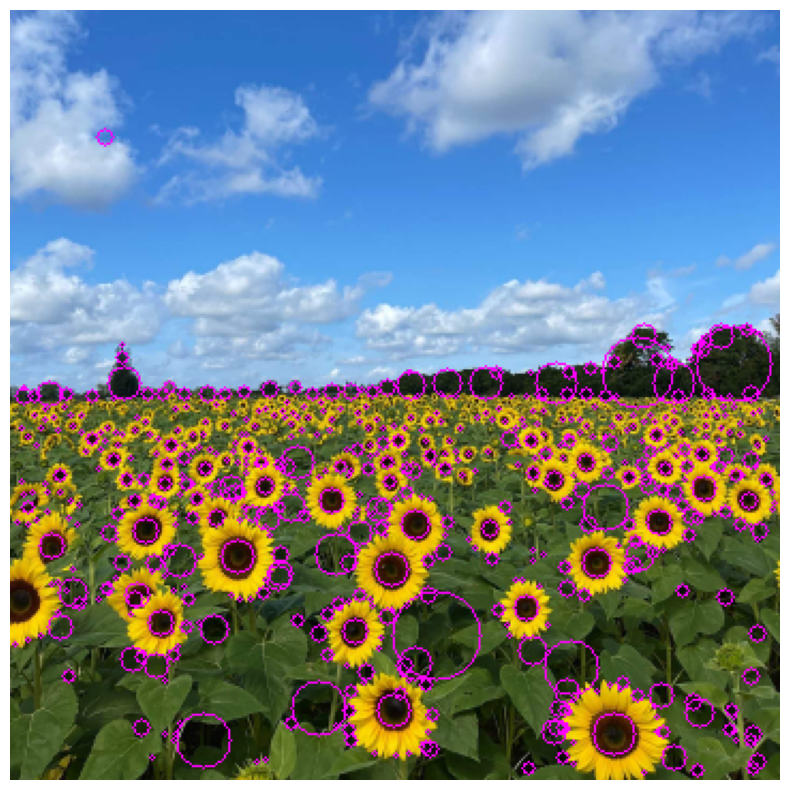

In [61]:
plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(output, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

In [64]:
print('Largest circles: x, y, radius, sigma')
print(np.round(circles[:10, :4], 2))



Largest circles: x, y, radius, sigma
[[199.   292.    21.21  15.  ]
 [338.   165.    18.38  13.  ]
 [293.   169.    16.97  12.  ]
 [262.   307.    12.73   9.  ]
 [ 90.   341.    12.73   9.  ]
 [144.   326.    12.73   9.  ]
 [278.   232.    11.31   8.  ]
 [310.   174.     9.9    7.  ]
 [152.   254.     9.9    7.  ]
 [255.   174.     9.9    7.  ]]
